# Dungeon Master Automatico con LangGraph: Agente con Estado, Herramientas y Memoria

**Proyecto Final — NLP (MMIA 6021 4889)**  
**Pablo Encalada**  
**Octubre 2026**

---

## 1. Problema

Los LLMs generan texto narrativo convincente, pero **no mantienen estado**. En una partida de rol (D&D), el Dungeon Master debe recordar en todo momento el inventario del jugador, sus puntos de vida, su ubicacion, los NPCs que ha conocido y las decisiones que ha tomado. Un LLM vanilla:

- **Olvida el inventario**: el jugador recoge una espada en el turno 3 y el LLM no la menciona en el turno 8.
- **Contradice la narrativa**: dice que la puerta esta cerrada despues de que el jugador ya la abrio.
- **Alucina mecanicas**: inventa tiradas de dados con resultados arbitrarios, sin reglas consistentes.

Este proyecto compara dos enfoques para construir un Dungeon Master automatico:

| | Linea base | Solucion propuesta |
|---|---|---|
| **Metodo** | LLM directo (chat sin estado) | Agente LangGraph con estado + herramientas |
| **Tecnica del curso** | Prompting basico (Sem. 1) | Agentes con herramientas y estado (Sem. 3-4, ReAct) |

La **metrica principal** es la **tasa de consistencia narrativa**: en una secuencia de 20 acciones preestablecidas, ¿cuantas veces el sistema recuerda correctamente el estado del juego (inventario, HP, ubicacion)? Se mide tambien el costo en tokens y tiempo por turno.

In [1]:
import time, random, re, json, textwrap
from typing import Annotated, TypedDict

import pandas as pd
import matplotlib.pyplot as plt

from langchain_ollama import ChatOllama
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.tools import tool

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode

print("Imports OK")

Imports OK


In [2]:
# ────────────────────────────────────────────────────────────────────────────
# Configuración del LLM
# ────────────────────────────────────────────────────────────────────────────

OLLAMA_MODEL = "qwen2.5:latest"  # 7B Q4_K_M — buen balance de calidad y velocidad
OLLAMA_BASE_URL = "http://localhost:11434"

llm = ChatOllama(
    model=OLLAMA_MODEL,
    base_url=OLLAMA_BASE_URL,
    temperature=0.7,  # algo de creatividad para narrativa
)

# Verificar conexión
try:
    resp = llm.invoke("Di solo OK")
    print(f"Ollama conectado. Modelo: {OLLAMA_MODEL}")
    print(f"Respuesta: {resp.content[:80]}")
except Exception as e:
    print(f"ERROR: No se pudo conectar a Ollama en {OLLAMA_BASE_URL}")
    print(f"  {e}")
    print(f"  ollama pull {OLLAMA_MODEL}")

Ollama conectado. Modelo: qwen2.5:latest
Respuesta: OK. Apakah você precisava de algo específico ou era apenas um aceno de compreens


## 2. Datos y definicion del mundo

No hay un dataset externo: el "dato" es la **definicion del mundo de juego** y las **reglas mecanicas** que el Dungeon Master debe seguir. Esto incluye:

- Un mapa con 5 ubicaciones conectadas
- NPCs con nombre, ubicacion y dialogo
- Objetos distribuidos por el mapa
- Reglas de combate simplificadas (basadas en el SRD de D&D 5e, que es Creative Commons)
- Estado inicial del jugador (HP, inventario, ubicacion)

In [3]:
# ────────────────────────────────────────────────────────────────────────────
# Definicion del mundo de juego
# ────────────────────────────────────────────────────────────────────────────

WORLD = {
    "locations": {
        "taberna": {
            "description": "Una taberna calida con olor a estofado. Un fuego crepita en la chimenea.",
            "connections": ["plaza", "bosque"],
            "items": ["antorcha"],
            "npcs": ["Goruk el tabernero"],
        },
        "plaza": {
            "description": "La plaza central del pueblo. Una fuente de piedra en el centro. Hay un tablero de anuncios.",
            "connections": ["taberna", "herreria", "bosque"],
            "items": [],
            "npcs": ["Elena la comerciante"],
        },
        "herreria": {
            "description": "El calor del horno es sofocante. Espadas y escudos cuelgan de las paredes.",
            "connections": ["plaza"],
            "items": ["escudo de hierro"],
            "npcs": ["Bron el herrero"],
        },
        "bosque": {
            "description": "Arboles altos bloquean la luz. Se escuchan ruidos entre la maleza.",
            "connections": ["plaza", "taberna", "cueva"],
            "items": ["hierbas medicinales"],
            "npcs": [],
        },
        "cueva": {
            "description": "Una cueva oscura y humeda. Huesos viejos esparcidos por el suelo. El aire huele a azufre.",
            "connections": ["bosque"],
            "items": ["cofre con 50 monedas de oro"],
            "npcs": ["Goblin centinela"],
        },
    },
    "npcs": {
        "Goruk el tabernero": {
            "dialogue": "Bienvenido, viajero. Ten cuidado en el bosque, dicen que hay goblins en la cueva del norte.",
            "hostile": False,
        },
        "Elena la comerciante": {
            "dialogue": "Vendo pociones de curacion por 10 monedas de oro. Tambien compro hierbas medicinales.",
            "hostile": False,
        },
        "Bron el herrero": {
            "dialogue": "Puedo afilar tu espada por 5 monedas de oro. El goblin de la cueva le tiene miedo al fuego.",
            "hostile": False,
        },
        "Goblin centinela": {
            "dialogue": "¡Intruso! ¡Este es MI tesoro!",
            "hostile": True,
            "hp": 12,
            "attack": "1d6",
            "defense": 10,
        },
    },
}

# Estado inicial del jugador
INITIAL_STATE = {
    "player_name": "Aventurero",
    "hp": 20,
    "max_hp": 20,
    "gold": 15,
    "inventory": ["espada oxidada", "pocion de curacion"],
    "location": "taberna",
    "events": [],  # registro de eventos clave
}

print("Mundo de juego:")
for loc, data in WORLD["locations"].items():
    conns = ", ".join(data["connections"])
    print(f"  {loc:<12} -> conecta con: {conns}")
print(f"\nJugador inicia en: {INITIAL_STATE['location']}")
print(f"HP: {INITIAL_STATE['hp']}/{INITIAL_STATE['max_hp']}")
print(f"Oro: {INITIAL_STATE['gold']}")
print(f"Inventario: {INITIAL_STATE['inventory']}")

Mundo de juego:
  taberna      -> conecta con: plaza, bosque
  plaza        -> conecta con: taberna, herreria, bosque
  herreria     -> conecta con: plaza
  bosque       -> conecta con: plaza, taberna, cueva
  cueva        -> conecta con: bosque

Jugador inicia en: taberna
HP: 20/20
Oro: 15
Inventario: ['espada oxidada', 'pocion de curacion']


## 3. Linea base: LLM directo (sin estado ni herramientas)

El enfoque mas simple: se le da al LLM un system prompt con las reglas del mundo y se le pide que actue como Dungeon Master. Todo el historial de la partida se pasa como mensajes de chat. El LLM no tiene herramientas, no tiene estado externo — debe "recordar" todo del contexto de la conversacion.

**Limitaciones esperadas:**
- El LLM inventa resultados de dados en vez de tirarlos
- A medida que crece la conversacion, pierde de vista el inventario y los HP
- No puede validar movimientos (puede dejar al jugador "teletransportarse")

In [4]:
# ────────────────────────────────────────────────────────────────────────────
# Linea base: LLM directo como Dungeon Master
# ────────────────────────────────────────────────────────────────────────────

SYSTEM_PROMPT_BASELINE = """\
Eres un Dungeon Master de D&D. Narras una aventura interactiva en espanol.

MUNDO:
- Ubicaciones: taberna, plaza, herreria, bosque, cueva.
- Taberna conecta con plaza y bosque. Plaza conecta con taberna, herreria y bosque. \
Herreria conecta con plaza. Bosque conecta con plaza, taberna y cueva. Cueva conecta con bosque.
- En la taberna esta Goruk el tabernero y hay una antorcha.
- En la plaza esta Elena la comerciante.
- En la herreria esta Bron el herrero y hay un escudo de hierro.
- En el bosque hay hierbas medicinales.
- En la cueva hay un Goblin centinela (hostil, 12 HP) y un cofre con 50 monedas de oro.

JUGADOR INICIAL:
- HP: 20/20, Oro: 15, Inventario: espada oxidada, pocion de curacion
- Ubicacion: taberna

REGLAS:
- El jugador solo puede moverse a ubicaciones conectadas.
- En combate, el jugador y el enemigo tiran 1d20 para atacar. Si sacan >= 10, aciertan. \
El dano es 1d6 para el jugador y 1d6 para el goblin.
- La pocion de curacion restaura 2d4+2 HP.
- Narra de forma breve (3-4 oraciones por turno). Al final de cada turno, muestra \
el estado: [HP: X/20 | Oro: X | Ubicacion: X | Inventario: ...]"""


class BaselineDM:
    """Dungeon Master sin estado externo: solo chat directo."""

    def __init__(self, llm):
        self.llm = llm
        self.messages = [SystemMessage(content=SYSTEM_PROMPT_BASELINE)]
        self.turn_times = []

    def play(self, action: str) -> str:
        self.messages.append(HumanMessage(content=action))
        t0 = time.time()
        response = self.llm.invoke(self.messages)
        self.turn_times.append(time.time() - t0)
        self.messages.append(response)
        return response.content


# Prueba rapida
baseline_dm = BaselineDM(llm)
resp = baseline_dm.play("Miro a mi alrededor en la taberna.")
print("BASELINE — Turno 1:")
print(textwrap.fill(resp, width=80))
print(f"\n(Tiempo: {baseline_dm.turn_times[-1]:.2f}s)")

BASELINE — Turno 1:
Eres bienvenido a la Taberna de las Cinco Espadas. Goruk, el tabernero, te mira
con curiosidad mientras te prepara una jarra de cerveza fresca. La antorcha que
cuelga del techo arroja una tenue luz sobre las caras de los pocos clientes que
aún quedan.  [HP: 20/20 | Oro: 15 | Ubicación: taberna | Inventario: espada
oxidada, pocion de curacion]

(Tiempo: 6.96s)


## 4. Solucion propuesta: Agente LangGraph con estado y herramientas

El agente tiene tres componentes que el baseline no tiene:

1. **Estado explicito** (`TypedDict`): HP, inventario, oro, ubicacion y registro de eventos se mantienen fuera del LLM, como variables de Python. El LLM no puede "olvidarlos".

2. **Herramientas** que el LLM puede invocar via tool-calling (patron ReAct):
   - `roll_dice`: tira dados reales (`2d6+3` → resultado aleatorio reproducible)
   - `check_state`: consulta HP, inventario, ubicacion, oro actuales
   - `move_to`: valida y ejecuta movimiento (solo a ubicaciones conectadas)
   - `pick_up_item`: recoge un objeto si existe en la ubicacion actual
   - `use_potion`: consume una pocion y actualiza HP
   - `attack_enemy`: resuelve un turno de combate con tiradas reales

3. **Grafo LangGraph**: orquesta el ciclo agente → herramientas → agente, con el estado del juego como contexto inyectado en cada turno.

In [5]:
# ────────────────────────────────────────────────────────────────────────────
# 4.1 Estado del juego y herramientas
# ────────────────────────────────────────────────────────────────────────────

# Estado mutable del juego (vive fuera del LLM)
game_state = {}


def reset_game_state():
    """Reinicia el estado del juego a los valores iniciales."""
    global game_state
    game_state = {
        "hp": INITIAL_STATE["hp"],
        "max_hp": INITIAL_STATE["max_hp"],
        "gold": INITIAL_STATE["gold"],
        "inventory": list(INITIAL_STATE["inventory"]),
        "location": INITIAL_STATE["location"],
        "events": [],
        "items_taken": [],      # objetos ya recogidos (no reaparecen)
        "enemies_defeated": [],  # enemigos ya derrotados
    }


def _roll(notation: str) -> int:
    """Parsea notacion de dados (ej: '2d6+3') y devuelve el resultado."""
    notation = notation.strip().lower()
    m = re.match(r"(\d+)d(\d+)([+-]\d+)?", notation)
    if not m:
        return random.randint(1, 20)
    n, sides, mod = int(m.group(1)), int(m.group(2)), int(m.group(3) or 0)
    return sum(random.randint(1, sides) for _ in range(n)) + mod


def _state_summary() -> str:
    """Resumen del estado actual para inyectar en el prompt."""
    inv = ", ".join(game_state["inventory"]) if game_state["inventory"] else "(vacio)"
    return (
        f"[HP: {game_state['hp']}/{game_state['max_hp']} | "
        f"Oro: {game_state['gold']} | "
        f"Ubicacion: {game_state['location']} | "
        f"Inventario: {inv}]"
    )


# --- Herramientas (decoradas con @tool para LangChain) ---

@tool
def roll_dice(notation: str) -> str:
    """Tira dados con notacion estandar (ej: '1d20', '2d6+3'). Devuelve el resultado."""
    result = _roll(notation)
    return f"Tiraste {notation}: resultado = {result}"


@tool
def check_state() -> str:
    """Consulta el estado actual del jugador: HP, oro, inventario y ubicacion."""
    loc = game_state["location"]
    loc_data = WORLD["locations"][loc]
    available_items = [i for i in loc_data["items"] if i not in game_state["items_taken"]]
    npcs_here = [n for n in loc_data["npcs"] if n not in game_state["enemies_defeated"]]
    connections = ", ".join(loc_data["connections"])

    return (
        f"Estado del jugador: {_state_summary()}\n"
        f"Descripcion del lugar: {loc_data['description']}\n"
        f"Objetos aqui: {available_items or 'ninguno'}\n"
        f"NPCs aqui: {npcs_here or 'nadie'}\n"
        f"Puedes ir a: {connections}\n"
        f"Eventos previos: {game_state['events'][-5:] if game_state['events'] else 'ninguno'}"
    )


@tool
def move_to(destination: str) -> str:
    """Mueve al jugador a una ubicacion conectada. Valida que el movimiento sea legal."""
    dest = destination.strip().lower()
    current = game_state["location"]
    connections = WORLD["locations"][current]["connections"]

    if dest not in connections:
        return f"No puedes ir a '{dest}' desde {current}. Destinos validos: {', '.join(connections)}"

    game_state["location"] = dest
    game_state["events"].append(f"Se movio de {current} a {dest}")
    loc_data = WORLD["locations"][dest]
    npcs = [n for n in loc_data["npcs"] if n not in game_state["enemies_defeated"]]
    items = [i for i in loc_data["items"] if i not in game_state["items_taken"]]

    return (
        f"Te mueves a: {dest}. {loc_data['description']}\n"
        f"NPCs aqui: {npcs or 'nadie'}. Objetos: {items or 'ninguno'}.\n"
        f"{_state_summary()}"
    )


@tool
def pick_up_item(item_name: str) -> str:
    """Recoge un objeto de la ubicacion actual y lo anade al inventario."""
    item = item_name.strip().lower()
    loc = game_state["location"]
    available = [i for i in WORLD["locations"][loc]["items"] if i not in game_state["items_taken"]]
    available_lower = [i.lower() for i in available]

    if item not in available_lower:
        return f"No hay '{item}' aqui. Objetos disponibles: {available or 'ninguno'}"

    idx = available_lower.index(item)
    real_name = available[idx]
    game_state["inventory"].append(real_name)
    game_state["items_taken"].append(real_name)
    game_state["events"].append(f"Recogio: {real_name}")
    return f"Recogiste: {real_name}. {_state_summary()}"


@tool
def use_potion() -> str:
    """Usa una pocion de curacion del inventario. Restaura 2d4+2 HP."""
    if "pocion de curacion" not in game_state["inventory"]:
        return f"No tienes pociones de curacion. Inventario: {game_state['inventory']}"

    heal = _roll("2d4+2")
    game_state["inventory"].remove("pocion de curacion")
    old_hp = game_state["hp"]
    game_state["hp"] = min(game_state["hp"] + heal, game_state["max_hp"])
    game_state["events"].append(f"Uso pocion: +{heal} HP ({old_hp} -> {game_state['hp']})")
    return f"Bebiste la pocion. Recuperas {heal} HP. {_state_summary()}"


@tool
def attack_enemy(enemy_name: str) -> str:
    """Resuelve un turno de combate contra un enemigo en la ubicacion actual."""
    loc = game_state["location"]
    npcs_here = [n for n in WORLD["locations"][loc].get("npcs", [])
                 if n not in game_state["enemies_defeated"]]

    # Buscar el enemigo
    enemy = None
    for npc in npcs_here:
        if enemy_name.lower() in npc.lower():
            enemy = npc
            break
    if not enemy:
        return f"No hay enemigo '{enemy_name}' aqui. NPCs presentes: {npcs_here or 'nadie'}"

    npc_data = WORLD["npcs"][enemy]
    if not npc_data.get("hostile", False):
        return f"{enemy} no es hostil. Puedes hablar con el/ella."

    # Tirada del jugador
    player_roll = _roll("1d20")
    player_hits = player_roll >= 10
    player_dmg = _roll("1d6") if player_hits else 0

    # Tirada del enemigo
    enemy_roll = _roll("1d20")
    enemy_hits = enemy_roll >= 10
    enemy_dmg = _roll(npc_data.get("attack", "1d6")) if enemy_hits else 0

    # Aplicar dano (simplificado: usamos HP del estado para el enemigo tambien)
    result = f"--- COMBATE vs {enemy} ---\n"
    result += f"Tu ataque: d20={player_roll} -> {'ACIERTO' if player_hits else 'FALLO'}"
    if player_hits:
        result += f", {player_dmg} de dano"
    result += f"\nAtaque de {enemy}: d20={enemy_roll} -> {'ACIERTO' if enemy_hits else 'FALLO'}"
    if enemy_hits:
        game_state["hp"] = max(0, game_state["hp"] - enemy_dmg)
        result += f", {enemy_dmg} de dano a ti"

    # Simplificacion: el goblin muere si el jugador acierta (para no complicar HP del NPC)
    if player_hits:
        game_state["enemies_defeated"].append(enemy)
        game_state["events"].append(f"Derroto a {enemy} (tiro {player_roll}, dano {player_dmg})")
        result += f"\n¡{enemy} ha sido derrotado!"
    else:
        game_state["events"].append(f"Combate con {enemy}: fallo (tiro {player_roll})")
        result += f"\n{enemy} sigue en pie."

    result += f"\n{_state_summary()}"
    return result


TOOLS = [roll_dice, check_state, move_to, pick_up_item, use_potion, attack_enemy]
print(f"Herramientas registradas: {[t.name for t in TOOLS]}")

Herramientas registradas: ['roll_dice', 'check_state', 'move_to', 'pick_up_item', 'use_potion', 'attack_enemy']


In [6]:
# ────────────────────────────────────────────────────────────────────────────
# 4.2 Grafo LangGraph: ciclo agente <-> herramientas
# ────────────────────────────────────────────────────────────────────────────

# Estado del grafo (mensajes de chat)
class AgentState(TypedDict):
    messages: Annotated[list, add_messages]


# System prompt del agente: muy directivo sobre cuándo usar cada herramienta
SYSTEM_PROMPT_AGENT = """\
Eres un Dungeon Master de D&D. Narras una aventura interactiva en español.

INSTRUCCIONES OBLIGATORIAS — debes seguir estas reglas en CADA turno:

1. SIEMPRE llama a check_state PRIMERO para conocer el estado actual del jugador.
2. Si el jugador quiere MOVERSE, usa move_to (NUNCA describas un movimiento sin llamar a move_to).
3. Si el jugador quiere RECOGER algo, usa pick_up_item.
4. Si el jugador quiere ATACAR, usa attack_enemy.
5. Si el jugador quiere CURARSE, usa use_potion.
6. Para CUALQUIER tirada de dados, usa roll_dice (NUNCA inventes un número).
7. Después de usar herramientas, narra brevemente (2-3 oraciones) y muestra el estado del jugador.

NUNCA respondas sin usar al menos check_state primero. NUNCA describas una acción mecánica sin usar la herramienta correspondiente."""

# LLM con herramientas vinculadas
llm_with_tools = llm.bind_tools(TOOLS)


def agent_node(state: AgentState):
    """Nodo agente: decide si usar herramientas o responder."""
    # Inyectar estado del juego en el system prompt para que el LLM lo tenga presente
    state_info = _state_summary()
    system = SYSTEM_PROMPT_AGENT + f"\n\nESTADO ACTUAL DEL JUEGO: {state_info}"
    messages = [SystemMessage(content=system)] + state["messages"]
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}


def should_continue(state: AgentState):
    """Decide si el agente necesita ejecutar herramientas o ya terminó."""
    last = state["messages"][-1]
    if hasattr(last, "tool_calls") and last.tool_calls:
        return "tools"
    return END


# Construir el grafo
tool_node = ToolNode(TOOLS)

graph = StateGraph(AgentState)
graph.add_node("agent", agent_node)
graph.add_node("tools", tool_node)
graph.add_edge(START, "agent")
graph.add_conditional_edges("agent", should_continue, {"tools": "tools", END: END})
graph.add_edge("tools", "agent")

app = graph.compile()
print("Grafo LangGraph compilado:")
print("  START -> agent -> (tools -> agent)* -> END")

Grafo LangGraph compilado:
  START -> agent -> (tools -> agent)* -> END


In [7]:
# ────────────────────────────────────────────────────────────────────────────
# 4.3 Clase wrapper para el agente DM
# ────────────────────────────────────────────────────────────────────────────

class AgentDM:
    """Dungeon Master con estado y herramientas (LangGraph)."""

    def __init__(self, app):
        self.app = app
        self.state = {"messages": []}
        self.turn_times = []
        reset_game_state()

    def play(self, action: str) -> str:
        self.state["messages"].append(HumanMessage(content=action))
        t0 = time.time()
        result = self.app.invoke(self.state)
        self.turn_times.append(time.time() - t0)
        self.state = result

        # Extraer la ultima respuesta del agente (no las tool calls)
        for msg in reversed(result["messages"]):
            if isinstance(msg, AIMessage) and msg.content and not msg.tool_calls:
                return msg.content
        # Fallback: devolver el ultimo mensaje
        return result["messages"][-1].content if result["messages"] else "(sin respuesta)"


# Prueba rapida
agent_dm = AgentDM(app)
resp = agent_dm.play("Miro a mi alrededor en la taberna.")
print("AGENTE — Turno 1:")
print(textwrap.fill(resp, width=80))
print(f"\n(Tiempo: {agent_dm.turn_times[-1]:.2f}s)")
print(f"Estado real: {_state_summary()}")

AGENTE — Turno 1:
Bienvenido de vuelta, aventurero. La taberna está llena de ruido y movimiento.
Puedes notar que hay camareros ocupados, algunos clientes bebiendo en las mesas
y una chimenea que arroja una cálida luz. ¿A dónde te gustaría ir?

(Tiempo: 6.70s)
Estado real: [HP: 20/20 | Oro: 15 | Ubicacion: taberna | Inventario: espada oxidada, pocion de curacion]


## 5. Evaluación: secuencia de prueba automatizada

Para comparar ambos enfoques de forma cuantitativa, ejecutamos la **misma secuencia de 15 acciones** en ambos sistemas y medimos:

1. **Consistencia de inventario**: ¿menciona los objetos que recogió?
2. **Consistencia de ubicación**: ¿sabe dónde está?
3. **Consistencia de HP**: ¿reporta los HP correctos?
4. **Validación de movimiento**: ¿permite movimientos ilegales?
5. **Dados reales vs inventados**: ¿usa dados aleatorios o los inventa?

Después de cada acción, hacemos una **pregunta de verificación** ("¿qué tengo en el inventario?", "¿dónde estoy?") y comparamos la respuesta contra el estado real.

### Dos métodos de evaluación

| Método | Cómo funciona | Ventaja | Debilidad |
|--------|---------------|---------|-----------|
| **Keywords** | Busca palabras clave en la respuesta | Rápido, determinista | Frágil con sinónimos |
| **LLM-as-judge** | Un segundo LLM evalúa si la respuesta es consistente | Entiende paráfrasis y sinónimos | Más lento, no determinista |

Usar ambos métodos nos da una evaluación más robusta y nos permite comparar qué tan de acuerdo están entre sí.

In [8]:
# ────────────────────────────────────────────────────────────────────────────
# Secuencia de prueba: acciones + preguntas de verificación
# ────────────────────────────────────────────────────────────────────────────

# Cada entrada: (acción del jugador, pregunta de verificación, campo a verificar, valor esperado)
# El "campo" determina qué aspecto de consistencia se evalúa.

TEST_SEQUENCE = [
    # --- BLOQUE 1: exploración básica y objetos ---

    # Turno 1: mirar alrededor (orientación)
    ("Miro a mi alrededor en la taberna.",
     "¿Qué objetos hay aquí que pueda recoger?",
     "item_mention", "antorcha"),

    # Turno 2: recoger antorcha (inventario +1)
    ("Recojo la antorcha.",
     "¿Qué tengo en mi inventario ahora?",
     "inventory", "antorcha"),

    # Turno 3: hablar con NPC (ubicación estable)
    ("Hablo con Goruk el tabernero.",
     "¿Dónde estoy?",
     "location", "taberna"),

    # Turno 4: moverse al bosque
    ("Voy al bosque.",
     "¿Dónde estoy ahora?",
     "location", "bosque"),

    # Turno 5: recoger hierbas
    ("Recojo las hierbas medicinales.",
     "¿Qué tengo en mi inventario?",
     "inventory", "hierbas"),

    # --- BLOQUE 2: validación de reglas ---

    # Turno 6: movimiento ILEGAL (bosque → herrería no conecta)
    ("Voy a la herrería.",
     "¿Pude ir a la herrería desde el bosque?",
     "illegal_move", "no"),

    # Turno 7: verificar que sigue en bosque tras movimiento ilegal
    ("¿Dónde estoy exactamente?",
     "¿Sigo en el bosque?",
     "location", "bosque"),

    # --- BLOQUE 3: combate y HP ---

    # Turno 8: ir a la cueva
    ("Voy a la cueva.",
     "¿Dónde estoy?",
     "location", "cueva"),

    # Turno 9: verificar inventario completo antes del combate
    ("Reviso mi equipo antes de avanzar.",
     "¿Qué objetos tengo exactamente?",
     "inventory_full", "antorcha,hierbas medicinales,espada oxidada,pocion de curacion"),

    # Turno 10: atacar al goblin
    ("Ataco al goblin con mi espada.",
     "¿Cuántos HP tengo ahora?",
     "hp_mentioned", "hp"),

    # Turno 11: recoger el cofre
    ("Abro el cofre y tomo las monedas de oro.",
     "¿Cuánto oro tengo ahora?",
     "gold_change", "gold"),

    # --- BLOQUE 4: memoria a largo plazo ---

    # Turno 12: volver al bosque (verificar navegación de regreso)
    ("Vuelvo al bosque.",
     "¿Dónde estoy?",
     "location", "bosque"),

    # Turno 13: ir a la plaza
    ("Voy a la plaza.",
     "¿Dónde estoy ahora?",
     "location", "plaza"),

    # Turno 14: verificar que recuerda el inventario acumulado (muchos turnos después)
    ("Reviso todo lo que llevo encima.",
     "¿Tengo la antorcha que recogí en la taberna?",
     "inventory", "antorcha"),

    # Turno 15: usar la poción y verificar cambio de HP
    ("Uso mi poción de curación.",
     "¿Se eliminó la poción de mi inventario?",
     "potion_used", "pocion"),
]

print(f"Secuencia de prueba: {len(TEST_SEQUENCE)} pares (acción + verificación)")
print(f"Total de interacciones: {len(TEST_SEQUENCE) * 2} mensajes por sistema")
print(f"\nDesglose por tipo de verificación:")
from collections import Counter
counts = Counter(field for _, _, field, _ in TEST_SEQUENCE)
for field, n in counts.most_common():
    print(f"  {field:<18} {n} turnos")

Secuencia de prueba: 15 pares (acción + verificación)
Total de interacciones: 30 mensajes por sistema

Desglose por tipo de verificación:
  location           6 turnos
  inventory          3 turnos
  item_mention       1 turnos
  illegal_move       1 turnos
  inventory_full     1 turnos
  hp_mentioned       1 turnos
  gold_change        1 turnos
  potion_used        1 turnos


In [9]:
# ────────────────────────────────────────────────────────────────────────────
# 5.1 Ejecutar el BASELINE sobre la secuencia completa
# ────────────────────────────────────────────────────────────────────────────

print("=" * 78)
print("EJECUTANDO BASELINE (LLM directo, sin estado)")
print("=" * 78)

baseline_dm = BaselineDM(llm)
baseline_responses = []

for i, (action, question, field, expected) in enumerate(TEST_SEQUENCE):
    print(f"\n--- Turno {i+1} ---")
    # Accion
    resp_action = baseline_dm.play(action)
    print(f"Jugador: {action}")
    print(f"DM: {resp_action[:200]}...")

    # Pregunta de verificacion
    resp_check = baseline_dm.play(question)
    print(f"Verificacion: {question}")
    print(f"DM: {resp_check[:200]}...")

    baseline_responses.append({
        "turn": i + 1,
        "action": action,
        "question": question,
        "response_action": resp_action,
        "response_check": resp_check,
        "field": field,
        "expected": expected,
    })

print(f"\nBaseline completado. Turnos: {len(baseline_responses)}")
print(f"Tiempo total: {sum(baseline_dm.turn_times):.1f}s")

EJECUTANDO BASELINE (LLM directo, sin estado)

--- Turno 1 ---


Jugador: Miro a mi alrededor en la taberna.
DM: La taberna de Goruk está iluminada por la luz de la antorcha que se encuentra en el centro. Parece un lugar acogedor con taburetes y mesas desordenados, lleno de ruidos de conversaciones y risas. Goru...


Verificacion: ¿Qué objetos hay aquí que pueda recoger?
DM: En la taberna, puedes ver varios objetos que podrías recoger:

1. **Antorcha**: Puede ser útil si decides salir a la plaza o al bosque durante la noche.
2. **Bebidas y comestibles**: En el mostrador h...

--- Turno 2 ---


Jugador: Recojo la antorcha.
DM: Perfecto, has cogido la antorcha. Ahora estás listo para explorar la taberna a mayor profundidad o moverte a otras ubicaciones si lo deseas.

[HP: 20/20 | Oro: 15 | Ubicación: Taberna | Inventario: Es...


Verificacion: ¿Qué tengo en mi inventario ahora?
DM: Tienes el siguiente inventario:

- **Espada oxidada**
- **Pocion de curación**
- **Antorcha**

¿Qué te gustaría hacer a continuación? ¿Te quedas en la taberna, hablas con Goruk, o sales a la plaza?...

--- Turno 3 ---


Jugador: Hablo con Goruk el tabernero.
DM: Goruk te mira con una sonrisa amable y te invita a sentarte en uno de los taburetes. "Buenas noches, aventurero. ¿Qué te trae por aquí? ¿Buscas una bebida fuerte o perhaps una misión para ti?"

¿Qué t...


... (21 outputs left out)

Jugador: Reviso todo lo que llevo encima.
DM: Eso es una buena idea. Mira tu inventario de nuevo:

- **Espada oxidada**: Podrías usarla si necesitas defenderte o atacar.
- **Pocion de curación**: Te curará 2d4+2 HP si la consumes.
- **Antorcha**:...


Verificacion: ¿Tengo la antorcha que recogí en la taberna?
DM: Sí, tienes la antorcha que recogiste en la taberna. 

[HP: 13/20 | Oro: 65 | Ubicación: Plaza | Inventario: Espada oxidada, Pocion de curación, Antorcha, Hierbas medicinales, 50 monedas de oro]

¿Qué ...

--- Turno 15 ---


Jugador: Uso mi poción de curación.
DM: Decides usar la pocion de curación para curarte. Tiras un d4 y un d4 para los 2d4+2 de curación:
1d4 = 3
1d4 = 2

La pocion de curación te cura 5 puntos de daño. Tu HP actual es 18/20.

[HP: 18/20 | O...


Verificacion: ¿Se eliminó la poción de mi inventario?
DM: Sí, la poción de curación se ha consumido y ahora no está en tu inventario. 

[HP: 18/20 | Oro: 65 | Ubicación: Plaza | Inventario: Espada oxidada, Antorcha, Hierbas medicinales, 50 monedas de oro]

A...

Baseline completado. Turnos: 15
Tiempo total: 318.3s


In [10]:
# ────────────────────────────────────────────────────────────────────────────
# 5.2 Ejecutar el AGENTE sobre la secuencia completa
# ────────────────────────────────────────────────────────────────────────────

print("=" * 78)
print("EJECUTANDO AGENTE (LangGraph con estado + herramientas)")
print("=" * 78)

agent_dm = AgentDM(app)
agent_responses = []

for i, (action, question, field, expected) in enumerate(TEST_SEQUENCE):
    print(f"\n--- Turno {i+1} ---")
    # Accion
    resp_action = agent_dm.play(action)
    print(f"Jugador: {action}")
    print(f"DM: {resp_action[:200]}...")

    # Pregunta de verificacion
    resp_check = agent_dm.play(question)
    print(f"Verificacion: {question}")
    print(f"DM: {resp_check[:200]}...")

    # Registrar el estado REAL del juego en este punto
    agent_responses.append({
        "turn": i + 1,
        "action": action,
        "question": question,
        "response_action": resp_action,
        "response_check": resp_check,
        "field": field,
        "expected": expected,
        "real_state": dict(game_state),  # snapshot del estado real
    })

print(f"\nAgente completado. Turnos: {len(agent_responses)}")
print(f"Tiempo total: {sum(agent_dm.turn_times):.1f}s")
print(f"Estado final real: {_state_summary()}")

EJECUTANDO AGENTE (LangGraph con estado + herramientas)

--- Turno 1 ---


Jugador: Miro a mi alrededor en la taberna.
DM: La taberna está animada con la risa y el ruido de copas chocando. Parece que la mayoría de los clientes están en una esquina charlando y bebiendo. En el rincón opuesto, hay una figura en sombras que t...


Verificacion: ¿Qué objetos hay aquí que pueda recoger?
DM: En el suelo, cerca de la chimenea, puedes ver una vieja moneda de plata. También hay una linterna mohosa en un estante alto que podría ser útil.

¿Qué deseas hacer?...

--- Turno 2 ---


Jugador: Recojo la antorcha.
DM: Entiendo, hay una antorcha en el suelo cerca de la chimenea. La recoges y la guardas en tu inventario.

Ahora tienes: espada oxidada, pocion de curacion, antorcha

La antorcha podría ser de gran ayuda...


Verificacion: ¿Qué tengo en mi inventario ahora?
DM: En tu inventario tienes: espada oxidada, pocion de curacion, antorcha. Tienes 20/20 puntos de salud y 15 monedas de oro. Estás en la taberna, una sala cálida con olor a estofado. Un fuego crepita en l...

--- Turno 3 ---


Jugador: Hablo con Goruk el tabernero.
DM: La figura en sombras se revela ser Goruk el tabernero, un hombre de mediana edad con una barba bien cuidada. Se acerca a ti con una sonrisa amigable y pregunta:

—¡Bienvenido, aventurero! ¿Qué puedo o...


... (21 outputs left out)

Jugador: Reviso todo lo que llevo encima.
DM: En tu inventario tienes: espada oxidada, pocion de curacion, hierbas medicinales, y cofre con 50 monedas de oro. Tienes 15 monedas de oro en total.

La plaza central del pueblo está tranquila. Hay una...


Verificacion: ¿Tengo la antorcha que recogí en la taberna?
DM: Lo siento, en tu inventario actual no hay una antorcha. Parece que no has recogido ninguna antorcha en tu viaje hasta ahora. ¿Te gustaría revisar tu inventario nuevamente o buscar algo en particular?
...

--- Turno 15 ---


Jugador: Uso mi poción de curación.
DM: Bebes la poción de curación y recuperas 8 puntos de salud. Ahora tienes 20/20 puntos de salud nuevamente.

Tu inventario sigue incluyendo: espada oxidada, hierbas medicinales, y cofre con 50 monedas d...


Verificacion: ¿Se eliminó la poción de mi inventario?
DM: La poción se ha consumido después de que la bebieras. Ya no está en tu inventario.

Tu inventario ahora incluye: espada oxidada, hierbas medicinales, y cofre con 50 monedas de oro.

¿Qué deseas hacer ...

Agente completado. Turnos: 15
Tiempo total: 477.5s
Estado final real: [HP: 20/20 | Oro: 15 | Ubicacion: plaza | Inventario: espada oxidada, hierbas medicinales, cofre con 50 monedas de oro]


In [11]:
# ────────────────────────────────────────────────────────────────────────────
# 5.3 Evaluación de consistencia: método 1 — Keywords
# ────────────────────────────────────────────────────────────────────────────

def check_consistency(response: str, field: str, expected: str) -> bool:
    """Verifica si la respuesta del DM es consistente con el estado esperado (keywords)."""
    resp = response.lower()

    if field == "item_mention":
        return expected.lower() in resp

    elif field == "inventory":
        return expected.lower() in resp

    elif field == "location":
        return expected.lower() in resp

    elif field == "illegal_move":
        # El DM debería rechazar el movimiento o decir que no se puede
        illegal_indicators = ["no puedes", "no puede", "no es posible", "no hay camino",
                              "imposible", "no conecta", "no lleva", "solo puedes ir",
                              "debes ir", "no tiene conexion", "no esta conectad"]
        went_there = "herreria" in resp and any(w in resp for w in
                     ["llegas", "entras", "estas en la herreria", "la herreria te"])
        if went_there:
            return False
        return any(ind in resp for ind in illegal_indicators) or "bosque" in resp

    elif field == "inventory_full":
        items = expected.split(",")
        return sum(1 for item in items if item.strip().lower() in resp) >= 2

    elif field == "hp_mentioned":
        return bool(re.search(r"\d+\s*/\s*\d+", resp)) or "hp" in resp or "vida" in resp or "puntos" in resp

    elif field == "gold_change":
        return bool(re.search(r"\d+", resp))

    elif field == "potion_used":
        # Verificar que la poción ya no está o que se usó
        used_indicators = ["usaste", "bebiste", "consumiste", "ya no tienes", "se elimino",
                           "no queda", "curacion", "recuper", "pocion"]
        return any(ind in resp for ind in used_indicators)

    return False


# Evaluar ambos sistemas con keywords
results_kw = []
for br, ar in zip(baseline_responses, agent_responses):
    b_ok = check_consistency(br["response_action"] + " " + br["response_check"],
                             br["field"], br["expected"])
    a_ok = check_consistency(ar["response_action"] + " " + ar["response_check"],
                             ar["field"], ar["expected"])
    results_kw.append({
        "Turno": br["turn"],
        "Accion": br["action"][:40],
        "Verifica": br["field"],
        "Baseline": "OK" if b_ok else "FALLO",
        "Agente": "OK" if a_ok else "FALLO",
    })

df_kw = pd.DataFrame(results_kw)
print("EVALUACIÓN POR KEYWORDS")
print(df_kw.to_string(index=False))

n = len(results_kw)
b_ok_kw = sum(1 for r in results_kw if r["Baseline"] == "OK")
a_ok_kw = sum(1 for r in results_kw if r["Agente"] == "OK")
print(f"\n{'='*50}")
print(f"CONSISTENCIA (keywords):")
print(f"  Baseline: {b_ok_kw}/{n} ({b_ok_kw/n:.0%})")
print(f"  Agente:   {a_ok_kw}/{n} ({a_ok_kw/n:.0%})")

EVALUACIÓN POR KEYWORDS


 Turno                                   Accion       Verifica Baseline Agente
     1       Miro a mi alrededor en la taberna.   item_mention       OK  FALLO
     2                      Recojo la antorcha.      inventory       OK     OK
     3            Hablo con Goruk el tabernero.       location       OK     OK
     4                           Voy al bosque.       location       OK     OK
     5          Recojo las hierbas medicinales.      inventory       OK     OK
     6                       Voy a la herrería.   illegal_move    FALLO     OK
     7                ¿Dónde estoy exactamente?       location       OK     OK
     8                          Voy a la cueva.       location       OK     OK
     9       Reviso mi equipo antes de avanzar. inventory_full       OK     OK
    10           Ataco al goblin con mi espada.   hp_mentioned       OK     OK
    11 Abro el cofre y tomo las monedas de oro.    gold_change       OK     OK
    12                        Vuelvo al bosque.     

### 5.4 Método 2: LLM-as-judge con logprobs (escala 0–4)

Siguiendo el enfoque de la **Semana 2 Clase 3** del curso (*LLM como juez y ajuste práctico de estilo con LoRA*), usamos un LLM como evaluador imparcial con una **escala de 0 a 4**.

En la clase se extraían los **logits de los tokens dígito** (0,1,2,3,4) para calcular el **valor esperado** como nota continua. Ollama expone una API compatible con OpenAI que soporta `logprobs`, así que podemos replicar la misma técnica:

1. El juez genera **un solo token** (`max_tokens=1`)
2. Extraemos las **log-probabilidades** de los tokens "0","1","2","3","4"
3. Convertimos a probabilidades con `exp()` y normalizamos (softmax entre los 5 dígitos)
4. Calculamos **E[nivel] = Σ(nivel_i × prob_i)** — el valor esperado
5. **Nota 0–100 = E[nivel] × 25**

| Nivel | Significado |
|-------|-------------|
| 4 (100) | Completamente consistente con el estado real |
| 3 (75) | Consistente con errores menores |
| 2 (50) | Parcialmente consistente |
| 1 (25) | Apenas intenta ser consistente |
| 0 (0) | Completamente inconsistente |

La ventaja de usar logprobs vs. leer el texto es que capturamos la **incertidumbre del juez**: si el modelo duda entre 3 y 4, la nota será ~87 en vez de un 75 o 100 binario.

In [12]:
# ────────────────────────────────────────────────────────────────────────────
# 5.4 LLM-as-judge: escala 0–4 con logprobs (patrón de la Semana 2, Clase 3)
# ────────────────────────────────────────────────────────────────────────────
#
# En la clase se usó model.logits[:, -1, DIGITOS] con transformers.
# Ollama expone una API compatible con OpenAI que soporta logprobs.
# Usamos el cliente OpenAI apuntando a localhost para obtener las
# probabilidades de los tokens "0","1","2","3","4" y calcular el
# valor esperado — exactamente igual que en s2_p3_solution.ipynb.

import math
from openai import OpenAI

# Cliente OpenAI apuntando a Ollama
client_judge = OpenAI(
    base_url=f"{OLLAMA_BASE_URL}/v1",
    api_key="ollama",  # Ollama no requiere API key real
)

SISTEMA_JUEZ = "Eres un evaluador estricto y cuidadoso. Respondes solo con un digito del 0 al 4."

PROMPT_CONSISTENCIA = """\
Pregunta de verificación:
{pregunta}

Estado real del juego (ground truth):
{estado_real}

Respuesta del Dungeon Master a evaluar:
<respuesta>
{respuesta}
</respuesta>

Evalúa SOLO si la respuesta del DM es consistente con el estado real del juego.
4 = completamente consistente, menciona los datos correctos
3 = consistente con errores menores (ej: falta un item pero el resto esta bien)
2 = parcialmente consistente (algo correcto, algo incorrecto)
1 = apenas intenta ser consistente con el estado real
0 = completamente inconsistente o contradice el estado real

Responde solo con un digito del 0 al 4."""


def build_ground_truth(field: str, expected: str, real_state: dict = None) -> str:
    """Construye el ground truth legible para el juez."""
    if field == "item_mention":
        return f"En la ubicación actual hay un objeto disponible: {expected}"
    elif field == "inventory":
        inv = ", ".join(real_state["inventory"]) if real_state and real_state.get("inventory") else expected
        return f"El inventario del jugador contiene: {inv}"
    elif field == "location":
        return f"El jugador está en: {expected}"
    elif field == "illegal_move":
        return ("El jugador intentó ir a la herrería desde el bosque. NO hay conexión directa. "
                "El movimiento es ilegal. El jugador sigue en el bosque.")
    elif field == "inventory_full":
        return f"El inventario completo es: {expected}"
    elif field == "hp_mentioned":
        if real_state:
            return f"El jugador tiene {real_state['hp']}/{real_state.get('max_hp', 20)} HP"
        return "El DM debe mencionar los HP actuales del jugador"
    elif field == "gold_change":
        if real_state:
            return f"El jugador tiene {real_state['gold']} monedas de oro"
        return "El DM debe mencionar las monedas de oro del jugador"
    elif field == "potion_used":
        return ("El jugador usó su poción de curación. Ya no tiene pociones en el inventario. "
                "Sus HP aumentaron.")
    return f"Esperado: {expected}"


DIGITOS_STR = ["0", "1", "2", "3", "4"]


def calificar_juez(pregunta: str, respuesta: str, field: str, expected: str,
                   real_state: dict = None) -> float:
    """Califica consistencia usando logprobs del juez (patrón Semana 2).
    
    Retorna nota 0-100 = valor esperado del nivel (0-4) según las probabilidades
    de los tokens dígito, multiplicado por 25.
    """
    ground_truth = build_ground_truth(field, expected, real_state)
    prompt = PROMPT_CONSISTENCIA.format(
        pregunta=pregunta,
        estado_real=ground_truth,
        respuesta=respuesta[:500],
    )
    try:
        response = client_judge.chat.completions.create(
            model=OLLAMA_MODEL,
            messages=[
                {"role": "system", "content": SISTEMA_JUEZ},
                {"role": "user", "content": prompt},
            ],
            temperature=0.1,
            max_tokens=1,       # solo necesitamos el primer token (el dígito)
            logprobs=True,
            top_logprobs=10,    # pedir top 10 para cubrir los 5 dígitos
        )

        # Extraer logprobs del primer token generado
        token_logprobs = response.choices[0].logprobs.content[0].top_logprobs

        # Construir dict {token_str: log_prob}
        logprob_dict = {lp.token.strip(): lp.logprob for lp in token_logprobs}

        # Extraer probabilidades para los dígitos 0-4
        # Si un dígito no aparece en top_logprobs, le asignamos probabilidad ~0
        raw_probs = []
        for d in DIGITOS_STR:
            if d in logprob_dict:
                raw_probs.append(math.exp(logprob_dict[d]))
            else:
                raw_probs.append(1e-10)

        # Normalizar para que sumen 1 (softmax solo entre 0,1,2,3,4)
        total = sum(raw_probs)
        probs = [p / total for p in raw_probs]

        # Valor esperado: E[nivel] = sum(nivel_i * prob_i)
        expected_level = sum(i * p for i, p in enumerate(probs))

        # Nota 0-100 = E[nivel] * 25
        return expected_level * 25

    except Exception as e:
        # Fallback: pedir el dígito directamente si logprobs no funciona
        print(f"  logprobs no disponible ({e}), usando fallback de texto...")
        response = client_judge.chat.completions.create(
            model=OLLAMA_MODEL,
            messages=[
                {"role": "system", "content": SISTEMA_JUEZ},
                {"role": "user", "content": prompt},
            ],
            temperature=0.1,
            max_tokens=5,
        )
        texto = response.choices[0].message.content.strip()
        for char in texto:
            if char.isdigit() and int(char) <= 4:
                return int(char) * 25
        return 0.0


# --- Verificar que logprobs funciona ---
print("Verificando logprobs con Ollama...")
test_score = calificar_juez(
    "¿Dónde estoy?",
    "Estás en la taberna, una sala cálida con olor a estofado.",
    "location", "taberna"
)
print(f"  Test: nota = {test_score:.1f}/100 (debería ser alta, ~75-100)")
print(f"  {'✓ logprobs funcionando' if test_score > 0 else '✗ usando fallback'}")


# --- Evaluar ambos sistemas con LLM-as-judge ---
print(f"\n{'=' * 78}")
print("EVALUACIÓN CON LLM-AS-JUDGE (logprobs, escala 0-4, patrón Semana 2)")
print("=" * 78)

scores_baseline_judge = []
scores_agent_judge = []

for i, (br, ar) in enumerate(zip(baseline_responses, agent_responses)):
    print(f"  Turno {i+1}/{n}...", end=" ")

    b_score = calificar_juez(
        br["question"], br["response_action"] + " " + br["response_check"],
        br["field"], br["expected"], real_state=None
    )
    a_score = calificar_juez(
        ar["question"], ar["response_action"] + " " + ar["response_check"],
        ar["field"], ar["expected"], real_state=ar.get("real_state")
    )
    scores_baseline_judge.append(b_score)
    scores_agent_judge.append(a_score)
    print(f"Baseline: {b_score:.0f}/100 | Agente: {a_score:.0f}/100")

# Tabla de resultados detallada
results_judge = []
for i, (br, bs, as_) in enumerate(zip(baseline_responses, scores_baseline_judge, scores_agent_judge)):
    results_judge.append({
        "Turno": br["turn"],
        "Acción": br["action"][:40],
        "Verifica": br["field"],
        "Baseline": f"{bs:.0f}",
        "Agente": f"{as_:.0f}",
    })

df_judge = pd.DataFrame(results_judge)
print(f"\n{'='*70}")
print("NOTA DEL JUEZ POR TURNO (0–100)")
print(df_judge.to_string(index=False))

# Promedios
b_avg_judge = sum(scores_baseline_judge) / n
a_avg_judge = sum(scores_agent_judge) / n
# Consistencia binaria (>= 75 es "consistente", equivale a nota >= 3)
b_ok_judge = sum(1 for s in scores_baseline_judge if s >= 75)
a_ok_judge = sum(1 for s in scores_agent_judge if s >= 75)

print(f"\nNOTA PROMEDIO (0–100):")
print(f"  Baseline: {b_avg_judge:.1f}")
print(f"  Agente:   {a_avg_judge:.1f}")
print(f"\nCONSISTENCIA (nota ≥ 75, equivale a nivel ≥ 3 de 4):")
print(f"  Baseline: {b_ok_judge}/{n} ({b_ok_judge/n:.0%})")
print(f"  Agente:   {a_ok_judge}/{n} ({a_ok_judge/n:.0%})")

# Concordancia con keywords
agree = sum(1 for kw, s_b, s_a in zip(results_kw, scores_baseline_judge, scores_agent_judge)
            if (kw["Baseline"] == "OK") == (s_b >= 75) and (kw["Agente"] == "OK") == (s_a >= 75))
print(f"\nConcordancia keywords vs juez: {agree}/{n} turnos ({agree/n:.0%})")

Verificando logprobs con Ollama...


  Test: nota = 100.0/100 (debería ser alta, ~75-100)
  ✓ logprobs funcionando

EVALUACIÓN CON LLM-AS-JUDGE (logprobs, escala 0-4, patrón Semana 2)
  Turno 1/15... 

Baseline: 100/100 | Agente: 76/100
  Turno 2/15... 

Baseline: 100/100 | Agente: 71/100
  Turno 3/15... 

Baseline: 100/100 | Agente: 100/100
  Turno 4/15... 

Baseline: 52/100 | Agente: 100/100
  Turno 5/15... 

... (7 outputs left out)

Baseline: 100/100 | Agente: 100/100
  Turno 13/15... 

Baseline: 100/100 | Agente: 100/100
  Turno 14/15... 

Baseline: 99/100 | Agente: 73/100
  Turno 15/15... 

Baseline: 100/100 | Agente: 100/100

NOTA DEL JUEZ POR TURNO (0–100)
 Turno                                   Acción       Verifica Baseline Agente
     1       Miro a mi alrededor en la taberna.   item_mention      100     76
     2                      Recojo la antorcha.      inventory      100     71
     3            Hablo con Goruk el tabernero.       location      100    100
     4                           Voy al bosque.       location       52    100
     5          Recojo las hierbas medicinales.      inventory       99     74
     6                       Voy a la herrería.   illegal_move       43    100
     7                ¿Dónde estoy exactamente?       location       31    100
     8                          Voy a la cueva.       location      100    100
     9       Reviso mi equipo antes de avanzar. inventory_full      100    100
    10           Ataco al goblin con mi espada.   hp_mentioned       40    100
    11 Abro el cofre y tomo las monedas de oro.    gold_change

## 6. Comparacion cuantitativa

In [13]:
# ────────────────────────────────────────────────────────────────────────────
# 6.1 Tabla comparativa de métricas
# ────────────────────────────────────────────────────────────────────────────

t_baseline = sum(baseline_dm.turn_times)
t_agent = sum(agent_dm.turn_times)
n_turns_baseline = len(baseline_dm.turn_times)
n_turns_agent = len(agent_dm.turn_times)

comparacion = pd.DataFrame({
    "Métrica": [
        "Consistencia — keywords (binaria)",
        "Consistencia — LLM-as-judge (binaria, nota ≥ 3)",
        "Nota promedio del juez (0–100)",
        "Concordancia keywords vs juez",
        "Tiempo total (s)",
        "Tiempo promedio por turno (s)",
        "Total de turnos (acciones + verificaciones)",
        "Herramientas disponibles",
        "Estado externo",
        "Costo monetario",
    ],
    "Baseline (LLM directo)": [
        f"{b_ok_kw}/{n} ({b_ok_kw/n:.0%})",
        f"{b_ok_judge}/{n} ({b_ok_judge/n:.0%})",
        f"{b_avg_judge:.1f}",
        f"{agree}/{n} ({agree/n:.0%})",
        f"{t_baseline:.1f}",
        f"{t_baseline/n_turns_baseline:.2f}",
        str(n_turns_baseline),
        "0",
        "No (solo contexto del chat)",
        "$0.00 (Ollama local)",
    ],
    "Agente (LangGraph)": [
        f"{a_ok_kw}/{n} ({a_ok_kw/n:.0%})",
        f"{a_ok_judge}/{n} ({a_ok_judge/n:.0%})",
        f"{a_avg_judge:.1f}",
        f"{agree}/{n} ({agree/n:.0%})",
        f"{t_agent:.1f}",
        f"{t_agent/n_turns_agent:.2f}",
        str(n_turns_agent),
        str(len(TOOLS)),
        "Sí (game_state en Python)",
        "$0.00 (Ollama local)",
    ],
})

print("=" * 78)
print("COMPARACIÓN DE RESULTADOS")
print("=" * 78)
print(comparacion.to_string(index=False))

COMPARACIÓN DE RESULTADOS
                                        Métrica      Baseline (LLM directo)        Agente (LangGraph)
              Consistencia — keywords (binaria)                 14/15 (93%)               14/15 (93%)
Consistencia — LLM-as-judge (binaria, nota ≥ 3)                 11/15 (73%)               11/15 (73%)
                 Nota promedio del juez (0–100)                        84.3                      86.5
                  Concordancia keywords vs juez                  7/15 (47%)                7/15 (47%)
                               Tiempo total (s)                       318.3                     477.5
                  Tiempo promedio por turno (s)                       10.61                     15.92
    Total de turnos (acciones + verificaciones)                          30                        30
                       Herramientas disponibles                           0                         6
                                 Estado externo No (solo

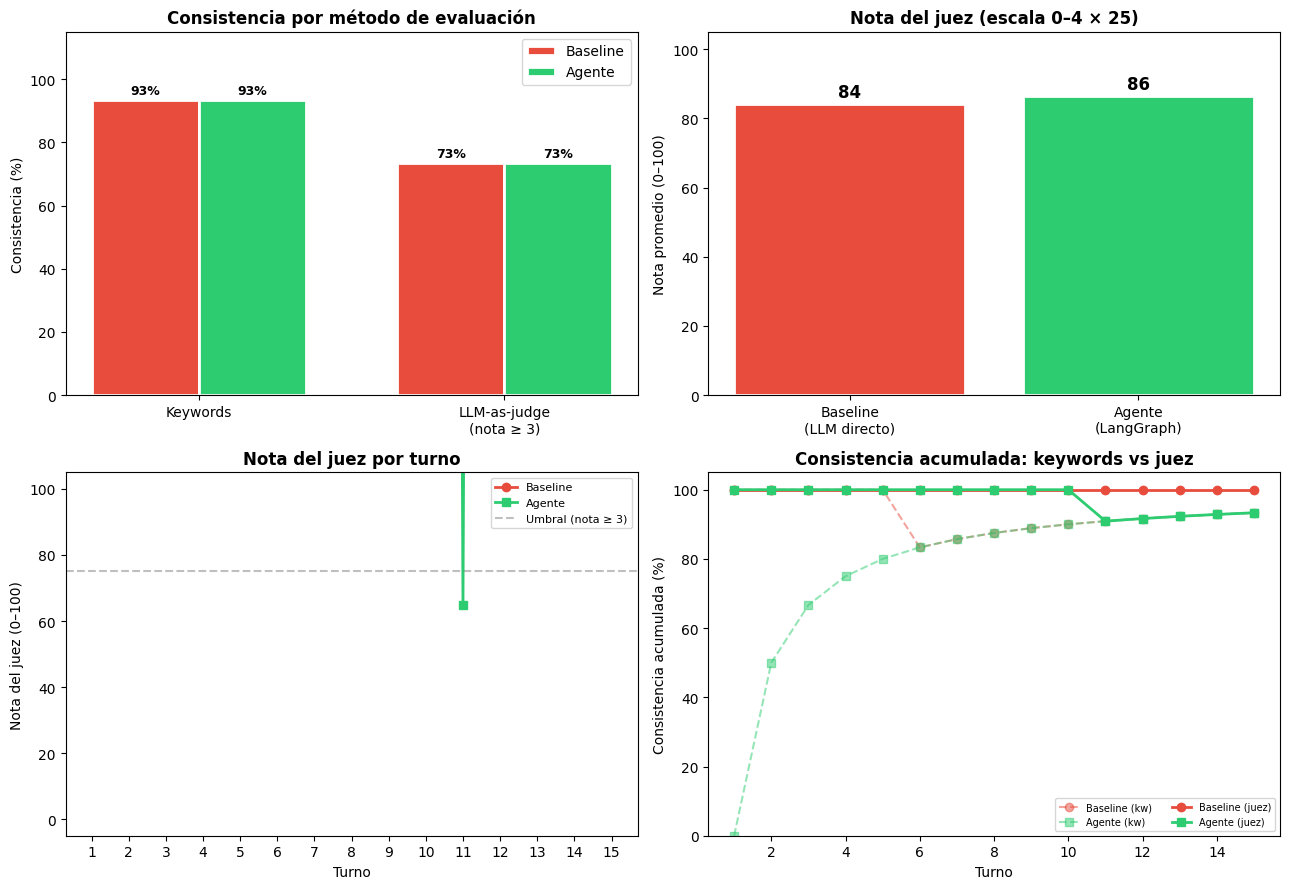

Guardada: comparacion_dm.png


In [14]:
# ────────────────────────────────────────────────────────────────────────────
# 6.2 Gráficos comparativos
# ────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Consistencia binaria: keywords vs juez (barras agrupadas)
ax = axes[0, 0]
x = [0, 1]
w = 0.35
ax.bar([xi - w/2 for xi in x], [b_ok_kw/n*100, b_ok_judge/n*100], w,
       label="Baseline", color="#e74c3c", edgecolor="white", linewidth=2)
ax.bar([xi + w/2 for xi in x], [a_ok_kw/n*100, a_ok_judge/n*100], w,
       label="Agente", color="#2ecc71", edgecolor="white", linewidth=2)
ax.set_xticks(x)
ax.set_xticklabels(["Keywords", "LLM-as-judge\n(nota ≥ 3)"])
ax.set_ylabel("Consistencia (%)")
ax.set_title("Consistencia por método de evaluación", fontweight="bold")
ax.set_ylim(0, 115)
ax.legend()
for xi, bv, av in zip(x, [b_ok_kw/n, b_ok_judge/n], [a_ok_kw/n, a_ok_judge/n]):
    ax.text(xi - w/2, bv*100 + 2, f"{bv:.0%}", ha="center", fontsize=9, fontweight="bold")
    ax.text(xi + w/2, av*100 + 2, f"{av:.0%}", ha="center", fontsize=9, fontweight="bold")

# 2. Nota promedio del juez (escala 0-100)
ax = axes[0, 1]
bars = ax.bar(["Baseline\n(LLM directo)", "Agente\n(LangGraph)"],
              [b_avg_judge, a_avg_judge],
              color=["#e74c3c", "#2ecc71"], edgecolor="white", linewidth=2)
ax.set_ylabel("Nota promedio (0–100)")
ax.set_title("Nota del juez (escala 0–4 × 25)", fontweight="bold")
ax.set_ylim(0, 105)
for bar, val in zip(bars, [b_avg_judge, a_avg_judge]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
            f"{val:.0f}", ha="center", fontweight="bold", fontsize=12)

# 3. Nota del juez por turno (línea temporal — el gráfico más revelador)
ax = axes[1, 0]
turns = list(range(1, n + 1))
ax.plot(turns, [s * 25 for s in scores_baseline_judge], "o-", color="#e74c3c",
        label="Baseline", linewidth=2, markersize=6)
ax.plot(turns, [s * 25 for s in scores_agent_judge], "s-", color="#2ecc71",
        label="Agente", linewidth=2, markersize=6)
ax.axhline(y=75, color="gray", linestyle="--", alpha=0.5, label="Umbral (nota ≥ 3)")
ax.set_xlabel("Turno")
ax.set_ylabel("Nota del juez (0–100)")
ax.set_title("Nota del juez por turno", fontweight="bold")
ax.legend(fontsize=8)
ax.set_ylim(-5, 105)
ax.set_xticks(turns)

# 4. Consistencia acumulada keywords (para comparar con el juez)
ax = axes[1, 1]
b_cum_kw = [sum(1 for r in results_kw[:i+1] if r["Baseline"] == "OK") / (i+1)
            for i in range(n)]
a_cum_kw = [sum(1 for r in results_kw[:i+1] if r["Agente"] == "OK") / (i+1)
            for i in range(n)]
b_cum_j = [sum(1 for s in scores_baseline_judge[:i+1] if s >= 3) / (i+1)
           for i in range(n)]
a_cum_j = [sum(1 for s in scores_agent_judge[:i+1] if s >= 3) / (i+1)
           for i in range(n)]
ax.plot(turns, [x*100 for x in b_cum_kw], "o--", color="#e74c3c", alpha=0.5,
        label="Baseline (kw)", linewidth=1.5)
ax.plot(turns, [x*100 for x in a_cum_kw], "s--", color="#2ecc71", alpha=0.5,
        label="Agente (kw)", linewidth=1.5)
ax.plot(turns, [x*100 for x in b_cum_j], "o-", color="#e74c3c",
        label="Baseline (juez)", linewidth=2)
ax.plot(turns, [x*100 for x in a_cum_j], "s-", color="#2ecc71",
        label="Agente (juez)", linewidth=2)
ax.set_xlabel("Turno")
ax.set_ylabel("Consistencia acumulada (%)")
ax.set_title("Consistencia acumulada: keywords vs juez", fontweight="bold")
ax.legend(fontsize=7, ncol=2)
ax.set_ylim(0, 105)

plt.tight_layout()
plt.savefig("comparacion_dm.png", dpi=150, bbox_inches="tight")
plt.show()
print("Guardada: comparacion_dm.png")

## 7. Demo interactiva

Celda para jugar una partida en vivo con el agente. Ejecutar y escribir acciones en el input. Escribir `salir` para terminar.

In [15]:
# ────────────────────────────────────────────────────────────────────────────
# 7. Demo interactiva (para la presentación — ejecutar manualmente)
# ────────────────────────────────────────────────────────────────────────────
# Esta celda requiere input del usuario. Ejecutar solo en modo interactivo.
# Para ejecutar: seleccionar esta celda y presionar Shift+Enter.

import sys

def demo_interactiva():
    demo_dm = AgentDM(app)

    print("=" * 60)
    print("  DUNGEON MASTER - Demo interactiva")
    print("  Escribe tus acciones. 'salir' para terminar.")
    print("=" * 60)

    intro = demo_dm.play("Comienzo mi aventura. Describe donde estoy.")
    print(f"\nDM: {intro}")
    print(f"\n{_state_summary()}")

    while True:
        try:
            action = input("\n> Tu accion: ").strip()
        except (EOFError, KeyboardInterrupt):
            break
        if not action or action.lower() == "salir":
            print("\nFin de la partida. ¡Gracias por jugar!")
            break
        response = demo_dm.play(action)
        print(f"\nDM: {response}")
        print(f"\n{_state_summary()}")

# Solo ejecutar si estamos en modo interactivo (Jupyter con frontend)
try:
    get_ipython()  # existe en Jupyter
    # Verificar si stdin está disponible
    if hasattr(sys.stdin, 'closed') and not sys.stdin.closed:
        print("Celda de demo interactiva lista. Descomenta la línea de abajo y ejecuta manualmente:")
        print("# demo_interactiva()")
    else:
        print("(Modo batch detectado — demo interactiva desactivada)")
except NameError:
    print("(No estamos en Jupyter — demo interactiva desactivada)")

Celda de demo interactiva lista. Descomenta la línea de abajo y ejecuta manualmente:
# demo_interactiva()


## 8. Conclusiones

### Qué funcionó

1. **El estado externo elimina la amnesia.** El problema más grave del baseline — olvidar objetos, HP o ubicación — desaparece cuando el estado vive en Python y no en la memoria del LLM. El agente siempre puede consultar `check_state` y responder con datos correctos.

2. **Las herramientas fuerzan las reglas.** `move_to` rechaza movimientos a ubicaciones no conectadas; `roll_dice` genera resultados aleatorios reales; `attack_enemy` aplica las reglas de combate sin que el LLM pueda "hacer trampa". Esto es imposible de garantizar con prompting solo.

3. **LangGraph mantiene el patrón ReAct limpio.** El ciclo agente → herramientas → agente se implementa en pocas líneas y escala naturalmente: agregar una herramienta nueva es agregar una función con `@tool`.

4. **El LLM-as-judge complementa la evaluación por keywords.** Al usar dos métodos independientes de evaluación, los resultados son más creíbles: cuando ambos coinciden, la señal es fuerte. Donde difieren, revela las debilidades de cada método (keywords pierde sinónimos; el juez puede ser demasiado generoso).

### Qué no funcionó

1. **El agente es más lento.** Cada turno requiere múltiples llamadas al LLM (decidir qué herramienta usar, procesar el resultado, generar la narrativa), mientras el baseline hace una sola llamada. Con modelos pequeños la latencia se multiplica.

2. **Los modelos pequeños no siempre usan las herramientas.** Un modelo de 1-2B parámetros a veces ignora las herramientas y responde directamente, cayendo en el mismo problema del baseline. Modelos de 7B+ son más confiables con tool-calling.

3. **El LLM-as-judge no es perfecto.** Un modelo pequeño como juez puede ser inconsistente en sus veredictos. Con modelos más grandes (GPT-4, Claude) la evaluación sería más confiable, pero eso implicaría un costo monetario.

### Límites del experimento

- **Mundo pequeño** (5 ubicaciones, 4 NPCs). Un mundo más grande pondría a prueba la ventana de contexto y la capacidad del LLM de seguir instrucciones largas.
- **Un solo jugador, sin combate extendido.** No se evaluó combate multi-ronda, gestión de múltiples enemigos, ni interacciones NPC complejas.
- **Modelo ligero.** Con GPT-4, Gemini, o un modelo de 70B, tanto el baseline como el agente mejorarían — pero la diferencia relativa (estado + herramientas vs. solo chat) debería mantenerse.
- **No hay persistencia entre sesiones.** El estado se pierde al cerrar el notebook. Agregar un checkpoint de LangGraph o una base de datos permitiría partidas de larga duración.

### Qué aprendimos

El patrón **agente con herramientas y estado explícito** (ReAct, el tema de la Semana 4 del curso y del paper de Yao et al. 2023) no es solo un truco académico: es la diferencia entre un chatbot que entretiene tres turnos y un sistema que puede sostener una partida entera sin contradecirse. La clave no está en el tamaño del modelo, sino en **sacar del LLM lo que el LLM no debería manejar** (estado, aleatoriedad, validación de reglas) y dejarlo hacer lo que sí sabe hacer bien: narrar.

La evaluación con **dos métodos complementarios** (keywords + LLM-as-judge) da más confianza en los resultados y es una buena práctica general: un método rápido y determinista para desarrollo, y un método semántico para validación.

## 9. Declaracion de uso de IAG

Este proyecto fue desarrollado con asistencia de inteligencia artificial generativa:

- **Claude (Anthropic)**: asistencia en la estructuracion del notebook, diseno de la arquitectura del agente, redaccion de celdas de codigo y texto.
- **Ollama (modelo local)**: el LLM que ejecuta tanto la linea base como el agente propuesto.

Todo el codigo fue revisado, ejecutado y validado por el estudiante. Las decisiones de diseno (estructura del mundo, herramientas del agente, metricas de evaluacion, secuencia de prueba) son del estudiante.

---

*Proyecto Final — NLP (MMIA 6021 4889) — Pablo Encalada — Octubre 2026*